In [4]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import os 
import scipy.sparse as sp

In [8]:
import networkx as ntx 
import torch.nn as nn
from functools import lru_cache


In [27]:
import numpy as np

def unitcell(w, d, t, e, m):
    """Pristine AGNR unit cell (2m x 2m) with correct honeycomb coordination."""
    m = int(m)
    base = (w + 1j * d) * np.eye(2 * m, dtype=complex)
    idy = np.arange(0, 2 * m - 1)
    base[idy, idy + 1] = t
    base[idy + 1, idy] = t
    
    # FIX 1: Disconnect spurious intra-cell rung for even widths
    if m % 2 == 0:
        base[m - 1, m] = 0
        base[m, m - 1] = 0
        
    idx = np.arange(0, m, 2)
    base[idx, 2 * m - 1 - idx] = t
    base[2 * m - 1 - idx, idx] = t
    return base


def T1_matrix(t, m):
    """Inter-cell hopping T (cell i -> i+1), connecting all m // 2 dimer rungs."""
    m = int(m)
    dim = 2 * m
    T = np.zeros((dim, dim), dtype=np.complex128)
    
    # FIX 2: Use m // 2 + 1 so n reaches 10 for m = 20
    n = np.arange(1, m // 2 + 1)
    T[2 * n - 1, 2 * m - 2 * n] = t
    return T


def rho_matrix(t, m):
    """Contact coupling operator."""
    m = int(m)
    dim = 2 * m
    rho = np.zeros((dim, dim), dtype=complex)
    
    # FIX 2: Include all m // 2 contact couplings
    for n in range(1, m // 2 + 1):
        idx = 2 * n - 1
        rho[idx, idx] = t
    return rho

In [10]:
DEVICE_COMBS = {}


def _get_device_combs(width: int) -> np.ndarray:
    """
    Return (global cached) device combinations for a given width.
    Each row is (i, j) with i in [0..99] and j in [0..width-1].
    """
    width = int(2*width)
    if width not in DEVICE_COMBS:
        # Build once, store once
        DEVICE_COMBS[width] = np.stack(
            np.meshgrid(np.arange(100), np.arange(width), indexing="ij"),
            axis=-1
        ).reshape(-1, 2)
    return DEVICE_COMBS[width]


@lru_cache(maxsize=2048)
def chosen_for_config(n: int, width: int, config: int) -> np.ndarray:
    """
    Return n rows selected deterministically by given config.
    Completely cached.
    """
    n = int(n)
    width = int(width)
    config = int(config)

    device_combs = _get_device_combs(width)

    rng = np.random.RandomState(config)
    idx = rng.choice(len(device_combs), size=n, replace=False)
    return device_combs[idx]


def possible_combs(n: int, width: int):
    n = int(n)
    width = int(width)

    def combs_for_seed(seed: int):
        return chosen_for_config(n, width, seed)

    return combs_for_seed


def unidevice(w, d, t, e, size, config, n, numberofunitcell, combs_fn=None):
    """
    Build a device Hamiltonian unit with impurities inserted at positions
    determined by 'config'. Uses vectorised assignments where possible.
    """

    size = int(size)

    
    if combs_fn is None:
        combs_fn = possible_combs(int(n), int(size))

    # Chosen impurity coordinates
    imps = combs_fn(int(config))
    x = imps[:, 0]
    y = imps[:, 1]

    z = int(numberofunitcell)

    # Base Hamiltonian (already cached inside your unitcell_leads)
    mat = unitcell(w, d, t, e, int(size))

    # Identify impurities in unitcell z
    mask = (x == z)
    if not np.any(mask):
        return mat  # fast path return

    imp_indices = y[mask]

    # Vectorised diagonal modification
    diag_val = (w + 1j*d - 0.5)
    mat[imp_indices, imp_indices] = diag_val

    return mat


In [11]:
leads_path = os.path.expanduser("~/atlas_store/leads/agnr_cell_v2/size_20/leads_20.npy")

In [13]:
leads = np.load(leads_path, allow_pickle=True)
leads.shape

(300, 40, 40)

(-0.002, 2.5)

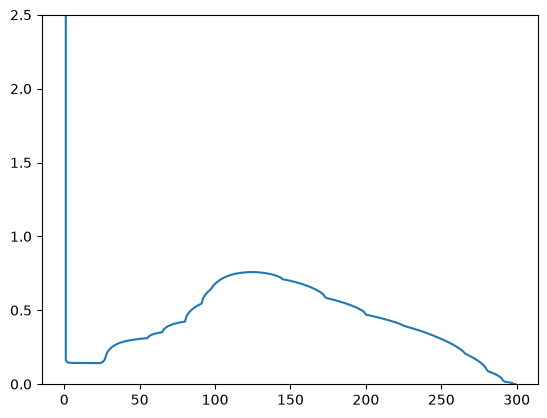

In [24]:
plt.plot([-np.imag(leads[x][3,3]) for x in range(300)])
plt.ylim([-.002, 2.5])

In [30]:
def device_transmission(w, d, t, e, size, config, concentration):
    ene = int(w * 100)
    m = size
    dim = 2 * m
    I = np.eye(dim, dtype=complex)

    # 1. Lead Surface Green's Functions:
    left = leads[ene]                   # Left lead surface Green's function
    #P = np.eye(dim)[::-1]
    #right = P @ left @ P                  # Right lead surface Green's function (g_R = P g_L P)

    # 2. Hopping Matrices:
    #T1 = T1_matrix(t, m)     
    tin = T1_matrix(t, m)
    tin_d = tin.T             # Forward hopping T
    #Tcon = connection(t, m)               # Backward hopping T^\dagger
    rho = rho_matrix(t, m)                # Contact operator \[Rho]

    # 3. Device Propagation (100 Unit Cells):
    combs_fn = possible_combs(concentration, size)
    g_new = left

    for i in range(100):
        unit_i = unidevice(w, d, t, e, size, config, concentration, i, combs_fn=combs_fn)
        gd = np.linalg.inv(unit_i)
        G = np.linalg.solve(I - gd @ tin_d @ g_new @ tin, gd)
        g_new = G

    left_device = g_new

    # 4. Connected Interface Green's Functions using Mathematica's rho matrix:
    IL = np.linalg.solve(I - left_device @ rho @ left @ rho, left_device)
    IR = np.linalg.solve(I - left @ rho @ left_device @ rho, left)

    # 5. Spectral Functions & Non-local Cross Green's Function:
    gdd = IL - IL.conj().T
    grr = IR - IR.conj().T

    Gnonlocal = left @ rho @ IL
    GNON = Gnonlocal - Gnonlocal.conj().T

    # 6. Mathematica Trace Calculation:
    term1 = gdd @ rho @ grr @ rho
    term2 = rho @ GNON @ rho @ GNON

    tr1 = np.abs(np.trace(term1 - term2))

    return tr1


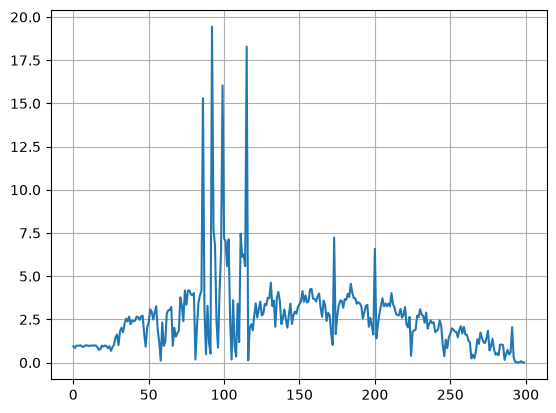

In [33]:
plt.grid()
plt.plot([device_transmission(w, 1e-5, 1, 0, 20, 40, 70) for w in np.arange(0,3,0.01)])
